# CIS 3400 Advanced Programming — Week 7
## Exploring & Visualizing Real Data with Python
### U.S. Airline On-Time Performance — June 2026

**Name:** Alan Rosales  
**Date:** September 28, 2026

---

## Today's Goal

Today we will use **real U.S. airline flight records** to follow a complete Exploratory Data Analysis (EDA) workflow.

Our overall question is:

> **What can June 2026 flight data tell airline and airport managers about delays and operational patterns?**

We will work through:

**Question → Inspect → Clean → Transform → Group/Aggregate → Visualize → Interpret → Communicate**

### Individual Submission

Follow along during class, run the code, and complete every **STOP & ANSWER** section in your own words.

You will submit this completed notebook individually in Blackboard.

### AI / VIBE Coding

AI may help you understand code, debug, or explore an idea. However, **you are responsible for understanding the code and interpreting the results.**


# 1. Import Our Python Libraries

We will use:

- **pandas** — working with tables/DataFrames
- **matplotlib** — creating visualizations


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 70)


# 2. Load the Real BTS Flight Data

Upload the June 2026 BTS CSV to Colab, or place it in the same folder as this notebook if using Jupyter/VS Code.

Change the filename below **only if your downloaded file has a different name**.


In [4]:
FILE = "airline_ontime_2026.csv"

df = pd.read_csv(FILE, low_memory=False)

print("Data loaded!")
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")


Data loaded!
Rows: 262,838
Columns: 64


## STOP & ANSWER 1 — Before We Analyze

A row in this dataset represents one scheduled flight.

Before looking closely at the results, what is **one pattern** you expect we might find in airline delays?

**Your prediction:**  
I predict that a lot of the delays will be caused by weather


# 3. Inspect Before You Analyze


In [5]:
display(df.head())


,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,ORIGIN_WAC,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,DEST_STATE_FIPS,DEST_STATE_NM,DEST_WAC,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DELAY_NEW,DEP_DEL15,DEP_DELAY_GROUP,DEP_TIME_BLK,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DELAY_NEW,ARR_DEL15,ARR_DELAY_GROUP,ARR_TIME_BLK,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,FLIGHTS,DISTANCE,DISTANCE_GROUP,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,FIRST_DEP_TIME,TOTAL_ADD_GTIME,LONGEST_ADD_GTIME
0,2026,2,6,1,1.0,6/1/2026 0:00,AA,19805.0,AA,N101NN,171.0,12478.0,1247805.0,31703.0,JFK,"New York, NY",NY,36.0,New York,22.0,12892.0,1289209.0,32575.0,LAX,"Los Angeles, CA",CA,6.0,California,91.0,600.0,553.0,-7.0,0.0,0.0,-1.0,0600-0659,18.0,611.0,854.0,10.0,915.0,904.0,-11.0,0.0,0.0,-1.0,0900-0959,0.0,NaN,0.0,375.0,371.0,343.0,1.0,2475.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026,2,6,1,1.0,6/1/2026 0:00,AA,19805.0,AA,N101NN,177.0,12478.0,1247805.0,31703.0,JFK,"New York, NY",NY,36.0,New York,22.0,14771.0,1477104.0,32457.0,SFO,"San Francisco, CA",CA,6.0,California,91.0,2030.0,2023.0,-7.0,0.0,0.0,-1.0,2000-2059,32.0,2055.0,14.0,7.0,2359.0,21.0,22.0,22.0,1.0,1.0,2300-2359,0.0,NaN,0.0,389.0,418.0,379.0,1.0,2586.0,11.0,0.0,0.0,22.0,0.0,0.0,NaN,NaN,NaN
2,2026,2,6,1,1.0,6/1/2026 0:00,AA,19805.0,AA,N101NN,238.0,12892.0,1289209.0,32575.0,LAX,"Los Angeles, CA",CA,6.0,California,91.0,12478.0,1247805.0,31703.0,JFK,"New York, NY",NY,36.0,New York,22.0,1010.0,1002.0,-8.0,0.0,0.0,-1.0,1000-1059,16.0,1018.0,1809.0,14.0,1843.0,1823.0,-20.0,0.0,0.0,-2.0,1800-1859,0.0,NaN,0.0,333.0,321.0,291.0,1.0,2475.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026,2,6,1,1.0,6/1/2026 0:00,AA,19805.0,AA,N102NN,10.0,12892.0,1289209.0,32575.0,LAX,"Los Angeles, CA",CA,6.0,California,91.0,12478.0,1247805.0,31703.0,JFK,"New York, NY",NY,36.0,New York,22.0,2154.0,2152.0,-2.0,0.0,0.0,-1.0,2100-2159,14.0,2206.0,612.0,5.0,620.0,617.0,-3.0,0.0,0.0,-1.0,0600-0659,0.0,NaN,0.0,326.0,325.0,306.0,1.0,2475.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026,2,6,1,1.0,6/1/2026 0:00,AA,19805.0,AA,N102NN,2.0,12892.0,1289209.0,32575.0,LAX,"Los Angeles, CA",CA,6.0,California,91.0,12478.0,1247805.0,31703.0,JFK,"New York, NY",NY,36.0,New York,22.0,700.0,711.0,11.0,11.0,0.0,0.0,0700-0759,17.0,728.0,1520.0,7.0,1530.0,1527.0,-3.0,0.0,0.0,-1.0,1500-1559,0.0,NaN,0.0,330.0,316.0,292.0,1.0,2475.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


Dataset shape: (262838, 64)

Column names:
['YEAR', 'QUARTER', 'MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'FL_DATE', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_AIRLINE_ID', 'OP_CARRIER', 'TAIL_NUM', 'OP_CARRIER_FL_NUM', 'ORIGIN_AIRPORT_ID', 'ORIGIN_AIRPORT_SEQ_ID', 'ORIGIN_CITY_MARKET_ID', 'ORIGIN', 'ORIGIN_CITY_NAME', 'ORIGIN_STATE_ABR', 'ORIGIN_STATE_FIPS', 'ORIGIN_STATE_NM', 'ORIGIN_WAC', 'DEST_AIRPORT_ID', 'DEST_AIRPORT_SEQ_ID', 'DEST_CITY_MARKET_ID', 'DEST', 'DEST_CITY_NAME', 'DEST_STATE_ABR', 'DEST_STATE_FIPS', 'DEST_STATE_NM', 'DEST_WAC', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'DEP_DELAY_NEW', 'DEP_DEL15', 'DEP_DELAY_GROUP', 'DEP_TIME_BLK', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'ARR_DELAY_NEW', 'ARR_DEL15', 'ARR_DELAY_GROUP', 'ARR_TIME_BLK', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'FLIGHTS', 'DISTANCE', 'DISTANCE_GROUP', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_

In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262838 entries, 0 to 262837
Data columns (total 64 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   YEAR                   262838 non-null  int64  
 1   QUARTER                262838 non-null  int64  
 2   MONTH                  262838 non-null  int64  
 3   DAY_OF_MONTH           262838 non-null  int64  
 4   DAY_OF_WEEK            262837 non-null  float64
 5   FL_DATE                262837 non-null  object 
 6   OP_UNIQUE_CARRIER      262837 non-null  object 
 7   OP_CARRIER_AIRLINE_ID  262837 non-null  float64
 8   OP_CARRIER             262837 non-null  object 
 9   TAIL_NUM               262431 non-null  object 
 10  OP_CARRIER_FL_NUM      262837 non-null  float64
 11  ORIGIN_AIRPORT_ID      262837 non-null  float64
 12  ORIGIN_AIRPORT_SEQ_ID  262837 non-null  float64
 13  ORIGIN_CITY_MARKET_ID  262837 non-null  float64
 14  ORIGIN                 262837 non-nu

## STOP & ANSWER 2 — Know Your Data

1. How many rows are in the dataset?  
2. How many columns?  
3. Name **three columns** you think will be useful for understanding delays.  
4. Identify one column whose meaning you would need to investigate before using it.

**Your answers:**  
1. 607577 rows
2. 64 columns
3. WEATHER_DELAY, SECURITY_DELAY, LATE_AIRCRAFT_DELAY
4. CANCELLATION_CODE because of the small number of non-null entries

# 4. Select the Columns We Need

The original government dataset contains many fields. We do **not** need every field for every question.

Selecting useful columns makes our analysis easier to read and understand.

Notice: we keep the original `df` and create a smaller DataFrame called `flights`.


In [8]:
useful_columns = [
    "FL_DATE",
    "DAY_OF_WEEK",
    "OP_CARRIER",
    "OP_CARRIER_FL_NUM",
    "ORIGIN",
    "ORIGIN_CITY_NAME",
    "DEST",
    "DEST_CITY_NAME",
    "CRS_DEP_TIME",
    "DEP_TIME",
    "DEP_DELAY",
    "DEP_DEL15",
    "DEP_TIME_BLK",
    "CRS_ARR_TIME",
    "ARR_TIME",
    "ARR_DELAY",
    "ARR_DEL15",
    "ARR_TIME_BLK",
    "CANCELLED",
    "CANCELLATION_CODE",
    "DIVERTED",
    "AIR_TIME",
    "DISTANCE",
    "CARRIER_DELAY",
    "WEATHER_DELAY",
    "NAS_DELAY",
    "SECURITY_DELAY",
    "LATE_AIRCRAFT_DELAY"
]

flights = df[useful_columns].copy()

print("Original shape:", df.shape)
print("Working shape:", flights.shape)
display(flights.head())


Original shape: (262838, 64)
Working shape: (262838, 28)


,FL_DATE,DAY_OF_WEEK,OP_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,ORIGIN_CITY_NAME,DEST,DEST_CITY_NAME,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,DEP_TIME_BLK,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DEL15,ARR_TIME_BLK,CANCELLED,CANCELLATION_CODE,DIVERTED,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
0,6/1/2026 0:00,1.0,AA,171.0,JFK,"New York, NY",LAX,"Los Angeles, CA",600.0,553.0,-7.0,0.0,0600-0659,915.0,904.0,-11.0,0.0,0900-0959,0.0,NaN,0.0,343.0,2475.0,NaN,NaN,NaN,NaN,NaN
1,6/1/2026 0:00,1.0,AA,177.0,JFK,"New York, NY",SFO,"San Francisco, CA",2030.0,2023.0,-7.0,0.0,2000-2059,2359.0,21.0,22.0,1.0,2300-2359,0.0,NaN,0.0,379.0,2586.0,0.0,0.0,22.0,0.0,0.0
2,6/1/2026 0:00,1.0,AA,238.0,LAX,"Los Angeles, CA",JFK,"New York, NY",1010.0,1002.0,-8.0,0.0,1000-1059,1843.0,1823.0,-20.0,0.0,1800-1859,0.0,NaN,0.0,291.0,2475.0,NaN,NaN,NaN,NaN,NaN
3,6/1/2026 0:00,1.0,AA,10.0,LAX,"Los Angeles, CA",JFK,"New York, NY",2154.0,2152.0,-2.0,0.0,2100-2159,620.0,617.0,-3.0,0.0,0600-0659,0.0,NaN,0.0,306.0,2475.0,NaN,NaN,NaN,NaN,NaN
4,6/1/2026 0:00,1.0,AA,2.0,LAX,"Los Angeles, CA",JFK,"New York, NY",700.0,711.0,11.0,0.0,0700-0759,1530.0,1527.0,-3.0,0.0,1500-1559,0.0,NaN,0.0,292.0,2475.0,NaN,NaN,NaN,NaN,NaN


## STOP & ANSWER 3 — Why Make a Smaller DataFrame?

Why might it be useful to create `flights` instead of deleting unwanted columns from `df`?

**Your answer:**  
It would be useful to create a smaller dataframe rather than deleting the unwanted columns because there is a possibility that those columns can be used for a different purpose, and it would be best to not permanently delete any records.


# 5. Data Quality: Missing Values


In [9]:
missing = flights.isna().sum().sort_values(ascending=False)

display(
    pd.DataFrame({
        "Missing": missing,
        "Percent Missing": (missing / len(flights) * 100).round(1)
    }).head(15)
)


,Missing,Percent Missing
CANCELLATION_CODE,257666,98.0
LATE_AIRCRAFT_DELAY,201040,76.5
NAS_DELAY,201040,76.5
SECURITY_DELAY,201040,76.5
CARRIER_DELAY,201040,76.5
WEATHER_DELAY,201040,76.5
ARR_DELAY,6290,2.4
ARR_DEL15,6290,2.4
AIR_TIME,6290,2.4
ARR_TIME,5292,2.0


### Missing does NOT automatically mean bad data

Look at the delay-cause columns:

- `CARRIER_DELAY`
- `WEATHER_DELAY`
- `NAS_DELAY`
- `SECURITY_DELAY`
- `LATE_AIRCRAFT_DELAY`

A blank value may simply mean that the flight did not have a reportable delay of that type.

A diverted flight may also be missing a normal arrival delay because it did not complete the originally scheduled trip in the normal way.

**Data cleaning requires reasoning—not just deleting every row containing `NaN`.**


## STOP & ANSWER 4 — Think Like an Analyst

Choose **one column with missing values**.

Why might the value be missing? Would you automatically delete every row where that value is missing? Explain.

**Your answer:**  
CANCELLATION_CODE - The value might have majority missing values because most people did not cancel their flights. Rows with missing data should not be deleted because that would mean deleting every record with people who did not cancel their flights.


# 6. Check for Duplicate Rows


In [10]:
duplicate_count = flights.duplicated().sum()

print(f"Exact duplicate rows: {duplicate_count:,}")


Exact duplicate rows: 0


## STOP & ANSWER 5

Why could duplicate flight records cause a problem when calculating counts or percentages?

**Your answer:**  
Duplicate flight records can inadvertently affect calculations because adding records with the same data can cause a bulk in the mean


# 7. Fix the Date


In [11]:
print("Before conversion:", flights["FL_DATE"].dtype)

flights["FL_DATE"] = pd.to_datetime(flights["FL_DATE"], errors="coerce")

print("After conversion:", flights["FL_DATE"].dtype)
print("First date:", flights["FL_DATE"].min())
print("Last date:", flights["FL_DATE"].max())


Before conversion: object
After conversion: datetime64[ns]
First date: 2026-06-01 00:00:00
Last date: 2026-06-14 00:00:00


## STOP & ANSWER 6

Why is converting `FL_DATE` to a true datetime value useful?

**Your answer:**  
It highlights incorrect dates and increases ability to filter throught dates


# 8. Understand Cancelled and Diverted Flights


In [12]:
print("Cancelled flights:")
print(flights["CANCELLED"].value_counts(dropna=False))

print("\nDiverted flights:")
print(flights["DIVERTED"].value_counts(dropna=False))


Cancelled flights:
CANCELLED
0.0    257665
1.0      5172
NaN         1
Name: count, dtype: int64

Diverted flights:
DIVERTED
0.0    261720
1.0      1117
NaN         1
Name: count, dtype: int64


In [13]:
special = flights[
    (flights["CANCELLED"] == 1) | (flights["DIVERTED"] == 1)
]

display(
    special[
        ["FL_DATE", "OP_CARRIER", "ORIGIN", "DEST",
         "CANCELLED", "DIVERTED", "ARR_DELAY", "AIR_TIME"]
    ].head(10)
)


,FL_DATE,OP_CARRIER,ORIGIN,DEST,CANCELLED,DIVERTED,ARR_DELAY,AIR_TIME
7,2026-06-01,AA,DSM,CLT,0.0,1.0,NaN,NaN
64,2026-06-01,AA,DCA,MCO,0.0,1.0,NaN,NaN
367,2026-06-01,AA,AUS,MIA,1.0,0.0,NaN,NaN
377,2026-06-01,AA,MCO,LGA,0.0,1.0,NaN,NaN
410,2026-06-01,AA,DFW,DEN,0.0,1.0,NaN,NaN
426,2026-06-01,AA,IAH,CLT,1.0,0.0,NaN,NaN
874,2026-06-01,AA,PHX,CLT,0.0,1.0,NaN,NaN
1094,2026-06-01,AA,XNA,CLT,0.0,1.0,NaN,NaN
1237,2026-06-01,AA,OKC,CLT,0.0,1.0,NaN,NaN
1260,2026-06-01,AA,LGA,CLT,0.0,1.0,NaN,NaN


## STOP & ANSWER 7 — Important Cleaning Decision

Look at the cancelled/diverted examples.

Why might `ARR_DELAY` or `AIR_TIME` be missing for some of these flights?

Does that necessarily mean the data are incorrect?

**Your answer:**  
They might be missing because they were either cancelled flights or diverted flights


# 9. Create an Analysis DataFrame

For analyses specifically about **normal arrival delay**, we will exclude cancelled and diverted flights.

We are **not deleting them from the original data**. We are creating a new DataFrame appropriate for this particular question.


In [14]:
completed = flights[
    (flights["CANCELLED"] == 0) &
    (flights["DIVERTED"] == 0) &
    (flights["ARR_DELAY"].notna())
].copy()

print(f"All scheduled flight records: {len(flights):,}")
print(f"Completed flights used for arrival-delay analysis: {len(completed):,}")


All scheduled flight records: 262,838
Completed flights used for arrival-delay analysis: 256,548


# 10. BTS Already Gives Us a Useful Variable

`ARR_DEL15` indicates whether a flight arrived **15 or more minutes late**.

- `0` = No
- `1` = Yes

Let's see how many completed flights were delayed.


In [15]:
delay_counts = completed["ARR_DEL15"].value_counts().sort_index()
display(delay_counts)

delay_rate = completed["ARR_DEL15"].mean() * 100
print(f"Percent arriving 15+ minutes late: {delay_rate:.1f}%")


,count
ARR_DEL15,
0.0,194750
1.0,61798


Percent arriving 15+ minutes late: 24.1%


## STOP & ANSWER 8

Why is `ARR_DEL15` convenient for analysis compared with repeatedly writing a condition such as:

`ARR_DELAY >= 15`

**Your answer:**  
It is more convenient because it reduces clutter and it is easier to calculate with binary


# 11. Grouping and Aggregation: Delay by Airline


In [16]:
airline_summary = (
    completed.groupby("OP_CARRIER")
    .agg(
        Flights=("OP_CARRIER", "size"),
        AvgArrivalDelay=("ARR_DELAY", "mean"),
        MedianArrivalDelay=("ARR_DELAY", "median"),
        DelayRate=("ARR_DEL15", "mean")
    )
)

airline_summary["DelayRatePct"] = airline_summary["DelayRate"] * 100

airline_summary = airline_summary.sort_values("DelayRatePct", ascending=False)

display(airline_summary.round(2))


,Flights,AvgArrivalDelay,MedianArrivalDelay,DelayRate,DelayRatePct
OP_CARRIER,,,,,
WN,51570,13.09,1.0,0.31,30.59
AA,36711,19.40,-5.0,0.29,28.84
UA,31058,14.34,-4.0,0.26,26.46
G4,5245,18.76,-4.0,0.25,25.38
OH,8269,16.54,-9.0,0.25,24.50
F9,8012,10.05,-8.0,0.24,23.96
MQ,11949,10.08,-8.0,0.24,23.74
OO,31048,10.99,-6.0,0.23,22.71
B6,8626,4.06,-10.0,0.19,19.29


## STOP & ANSWER 9 — Mean vs. Median

Look at the average and median arrival delays.

Why can the **mean** and **median** tell different stories about flight delays?

**Your answer:**  
The mean number is the average of all flight delays, including the outliers, while the median is takes the middle number and is less affected by outliers

# 12. Visualize Airline Delay Rates


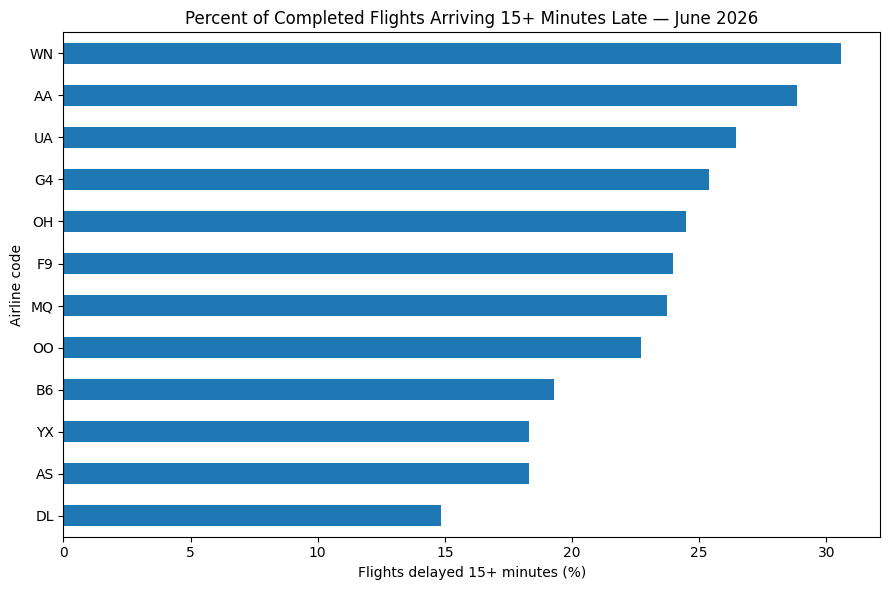

In [17]:
(
    airline_summary
    .sort_values("DelayRatePct")["DelayRatePct"]
    .plot(
        kind="barh",
        figsize=(9, 6),
        title="Percent of Completed Flights Arriving 15+ Minutes Late — June 2026"
    )
)

plt.xlabel("Flights delayed 15+ minutes (%)")
plt.ylabel("Airline code")
plt.tight_layout()
plt.show()


## STOP & ANSWER 10 — Chart → Insight

Do **not** simply say "this chart shows airline delays."

Write 2–3 sentences explaining:

1. What pattern should a manager notice?
2. What does this chart **not** tell us or prove?

**Your answer:**  
A manager should notice that flights with the flight code WN have the highest percentage of flights arriving more than 15 minutes late. This chart is not trying to prove which airline has worse service or less successful flights

# 13. What About Day of the Week?


In [18]:
day_names = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
}

completed["DAY_NAME"] = completed["DAY_OF_WEEK"].map(day_names)

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

day_summary = (
    completed.groupby("DAY_NAME")["ARR_DEL15"]
    .mean()
    .reindex(day_order) * 100
)

display(day_summary.round(1))


,ARR_DEL15
DAY_NAME,
Monday,25.0
Tuesday,17.5
Wednesday,21.5
Thursday,24.6
Friday,27.0
Saturday,23.4
Sunday,33.3


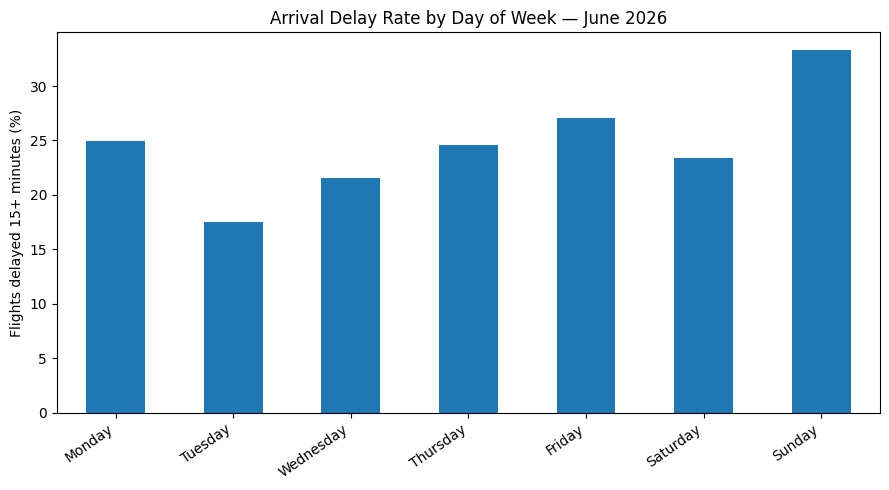

In [19]:
day_summary.plot(
    kind="bar",
    figsize=(9, 5),
    title="Arrival Delay Rate by Day of Week — June 2026"
)

plt.ylabel("Flights delayed 15+ minutes (%)")
plt.xlabel("")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## STOP & ANSWER 11

Which day has the highest delay rate? Which has the lowest?

Approximately how many **percentage points** separate them?

Would this result make you want to investigate further? Why?

**Your answer:**  
The day with the highest delay rate is Sunday and Tuesday has the lowest. ~17 percentage points separate them. It would make me want to investigate becuase I would expect weekends to have more flight delays since they are busier days, but Friday and Saturday don't rank too much higher than the other days


# 14. Does Time of Day Matter?


In [20]:
time_summary = (
    completed.groupby("DEP_TIME_BLK")["ARR_DEL15"]
    .agg(["count", "mean"])
)

time_summary["DelayRatePct"] = time_summary["mean"] * 100

display(time_summary.round(2))


,count,mean,DelayRatePct
DEP_TIME_BLK,,,
0001-0559,8220,0.08,8.15
0600-0659,17783,0.08,8.26
0700-0759,19541,0.11,11.31
0800-0859,17083,0.13,12.63
0900-0959,14455,0.15,14.73
1000-1059,16254,0.17,17.36
1100-1159,15561,0.19,19.05
1200-1259,15015,0.23,23.06
1300-1359,15189,0.25,25.46


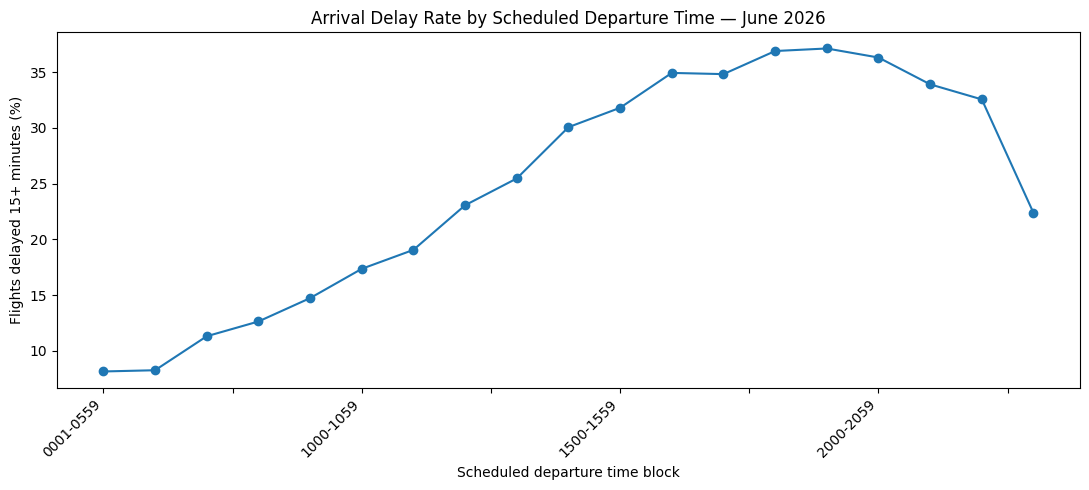

In [21]:
time_summary["DelayRatePct"].plot(
    kind="line",
    marker="o",
    figsize=(11, 5),
    title="Arrival Delay Rate by Scheduled Departure Time — June 2026"
)

plt.ylabel("Flights delayed 15+ minutes (%)")
plt.xlabel("Scheduled departure time block")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## STOP & ANSWER 12 — Find the Story

Describe the overall pattern you see across the day.

Does the visualization suggest that delay risk stays constant throughout the day?

**Your answer:**  
There are less delays earlier in the day, but there are more delays through the afternoon-evening. The risk of delay does not stay constant throught the day.


# 15. Which Airports Are Busiest?


In [22]:
origin_summary = (
    completed.groupby(["ORIGIN", "ORIGIN_CITY_NAME"])
    .agg(
        Flights=("ORIGIN", "size"),
        DelayRate=("ARR_DEL15", "mean")
    )
    .reset_index()
)

origin_summary["DelayRatePct"] = origin_summary["DelayRate"] * 100

busiest = origin_summary.sort_values("Flights", ascending=False).head(10)

display(busiest.round(2))


,ORIGIN,ORIGIN_CITY_NAME,Flights,DelayRate,DelayRatePct
240,ORD,"Chicago, IL",12749,0.30,30.25
89,DEN,"Denver, CO",12232,0.33,32.89
19,ATL,"Atlanta, GA",11627,0.16,15.95
90,DFW,"Dallas/Fort Worth, TX",11396,0.38,38.40
183,LAX,"Los Angeles, CA",7132,0.23,22.87
252,PHX,"Phoenix, AZ",6847,0.26,26.16
69,CLT,"Charlotte, NC",6551,0.23,23.40
297,SEA,"Seattle, WA",6530,0.20,19.86
181,LAS,"Las Vegas, NV",5891,0.27,26.96
299,SFO,"San Francisco, CA",5744,0.34,34.33


### Important analytical caution

A small airport with only a few flights could have an extreme percentage by chance.

When comparing groups, always consider **how many observations are in each group**.


# 16. Why Were Delayed Flights Delayed?


In [23]:
delay_causes = [
    "CARRIER_DELAY",
    "WEATHER_DELAY",
    "NAS_DELAY",
    "SECURITY_DELAY",
    "LATE_AIRCRAFT_DELAY"
]

cause_totals = completed[delay_causes].sum().sort_values(ascending=False)

display(cause_totals)


,0
LATE_AIRCRAFT_DELAY,1876758.0
CARRIER_DELAY,1476951.0
NAS_DELAY,1049626.0
WEATHER_DELAY,364330.0
SECURITY_DELAY,6304.0


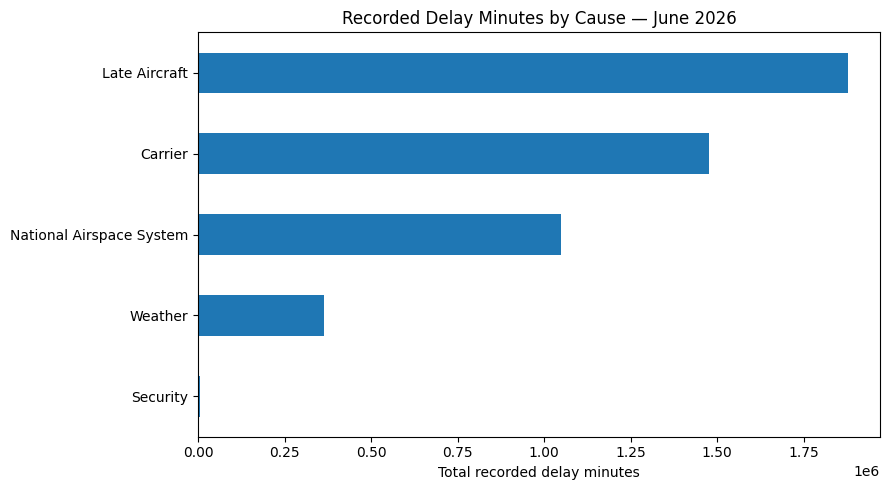

In [24]:
cause_totals.rename({
    "CARRIER_DELAY": "Carrier",
    "WEATHER_DELAY": "Weather",
    "NAS_DELAY": "National Airspace System",
    "SECURITY_DELAY": "Security",
    "LATE_AIRCRAFT_DELAY": "Late Aircraft"
}).sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Recorded Delay Minutes by Cause — June 2026"
)

plt.xlabel("Total recorded delay minutes")
plt.ylabel("")
plt.tight_layout()
plt.show()


## STOP & ANSWER 13

Which recorded delay category accounts for the most total minutes in this dataset?

Why should we be careful about saying that this category **caused all airline delays**?

**Your answer:**  
Most of the delay time comes from Late Aircraft. We should be careful becuase Carrier delays come close to Late Aircraft. Additionally, all other variables combined give a larger amount of delay minutes than Late Aircraft


# 17. Ask One Question of Your Own


Now use the dataset yourself.

Write **one additional question** that could be useful to an airline or airport manager.

Possible areas include:

- A particular airport
- A route
- Airline differences
- Distance
- Departure time
- Cancellation
- Delay cause

Do not simply repeat one of the questions we already answered.

### My Question

Which departure time is the most frequent?

In [30]:
# YOUR ANALYSIS
#
# Write Python that helps answer your question.
print("\nTop departure blocks:")
print(df["DEP_TIME_BLK"].value_counts().head(25))
# You may use Monday's examples and AI/VIBE coding for help.
# Be prepared to explain what your code does.



Top departure blocks:
DEP_TIME_BLK
0700-0759    19831
0600-0659    18105
0800-0859    17269
1700-1759    16784
1000-1059    16470
1100-1159    15778
1800-1859    15540
1300-1359    15471
1200-1259    15294
1500-1559    15051
0900-0959    14618
1600-1659    14613
1400-1459    14296
1900-1959    14234
2000-2059    12518
2100-2159     9153
0001-0559     8361
2200-2259     6765
2300-2359     2686
Name: count, dtype: int64


### What Did You Find?

Explain your result in **2–3 sentences in plain language**.

**Your interpretation:**  
The time where the most planes depart is 0700-0759. The time where the least planes depart is 2300-2359.


# 18. Your 60-Second Managerial Summary


Imagine an airline or airport manager asks:

> **"What should I remember from this analysis?"**

Give them your **three most important findings** from today's work.

Do not talk about pandas, DataFrames, or Python. Talk about the **data and what it suggests**.

### Finding 1
Most aircraft delays occur on Sundays

### Finding 2
Airline WN has the most delays 15+ minutes

### Finding 3
The majority of planes depart from 7:00-7:59 in the morning

### One thing management should investigate next
Management could investigate the reason why aircraft arrival delays happen in the ARR_DEL15 variable.

# 19. Exit Check


Complete these before submitting:

**One pandas command I understand better now:**  
df.describe()

**In my own words, `groupby()` lets us:**  
It lets us split data based on the column and helps do specific calculations

**One thing I learned about missing data:**  
Missing data in a record doesn't mean the whole record is bad

**One thing that makes a visualization useful instead of merely attractive:**  
A visualization shows trends in specific contexts and makes data easier to interpret

**One question I still have:**  
How can we make sure a column is not needed for an investigation of data?

---

# Submit to Blackboard

1. Make sure your name is at the top.
2. Make sure every **STOP & ANSWER** section is complete.
3. Make sure your own analysis runs.
4. Save/download the notebook as an `.ipynb` file.
5. Submit it **individually** in Blackboard.

Next class, you and a partner will apply this same workflow to a **different real dataset** without having all of the analysis written for you.
